# 로컬 LLM 모델별 비교 실험

Qwen3 1.7B · Gemma 2 2B · Llama 3.2 3B

실제 로컬 실행 결과를 담았습니다. 기본 셀을 다시 실행해도 모델을 재호출하지 않습니다.

## 1. 실험 목적과 조건

같은 실제 소스 1건을 한국어 보고서로 요약하도록 요청했습니다. 각 모델 3회, seed 42·43·44, temperature 0.2, 문맥 4096, 출력 상한 768토큰, CPU 4스레드입니다. 모델 순서는 회차별로 바꿨습니다. 다운로드 시간은 제외하고 요청별 모델 로드 시간은 포함합니다.

모델 크기·양자화·토크나이저·대화 템플릿은 서로 다릅니다. Qwen은 기존 앱의 비추론 템플릿을 사용했습니다. 같은 seed가 모델 간 같은 출력을 의미하지는 않습니다. 1개 과제의 결과이므로 전체 성능 순위로 일반화하지 않습니다.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# 실제 기록 사본은 이 노트북 안에도 저장돼 있습니다.
paths = [Path('model_family_comparison.ipynb'), Path('notebooks/model_family_comparison.ipynb')]
notebook_path = next(p for p in paths if p.exists())
snapshot = json.loads(notebook_path.read_text(encoding='utf-8'))['metadata']['benchmark_snapshot']
records = snapshot['records']
rows = []
for r in records:
    raw = r['raw']
    rows.append({'model':r['model'], 'repeat':r['repeat'], 'seconds':r['wall_seconds'],
                 'output_tokens':raw.get('eval_count'), 'done_reason':raw.get('done_reason'),
                 'load_seconds':raw.get('load_duration',0)/1e9})
df = pd.DataFrame(rows)
display(df.round(2))

,model,repeat,seconds,output_tokens,done_reason,load_seconds
0,gemma2:2b,1,67.07,305,stop,6.00
1,llama3.2:3b,1,101.66,449,stop,11.36
2,qwen3:1.7b,1,37.95,121,stop,15.28
3,gemma2:2b,2,69.53,292,stop,6.56
4,llama3.2:3b,2,117.01,502,stop,8.59
5,qwen3:1.7b,2,30.62,121,stop,6.39
6,gemma2:2b,3,55.67,252,stop,6.48
7,llama3.2:3b,3,82.27,427,stop,6.03
8,qwen3:1.7b,3,27.00,144,stop,4.78


## 2. 비교 자료와 정답 기준

배포본의 cloud_config.py 연결 검사 부분과 model_settings.json을 고정 사본으로 사용했습니다. 배포 성공·보고서 정확도·학습 성능은 이 소스만으로 입증할 수 없습니다.

In [2]:
for source in snapshot['protocol']['sources']:
    print(source['id'], source['file'], '\n', source['text'])

E1 cloud_config.py 
 """Streamlit Secrets의 모델 연결과 세션별 작업 공간을 관리합니다."""

import hashlib
import json
import os
import urllib.error
import urllib.parse
import urllib.request
import uuid


def ollama_connection():
    base = os.environ.get("OLLAMA_BASE_URL", "").strip().rstrip("/")
    if not base:
        raise ValueError("Streamlit Secrets에 OLLAMA_BASE_URL을 설정하세요.")
    parsed = urllib.parse.urlsplit(base)
    if (
        parsed.scheme not in {"http", "https"}
        or not parsed.hostname
        or parsed.username
        or parsed.password
        or parsed.query
        or parsed.fragment
    ):
        raise ValueError(
            "OLLAMA_BASE_URL은 인증정보·쿼리가 없는 http(s) 서버 주소여야 합니다."
        )
    headers = {"Content-Type": "application/json"}
    token = os.environ.get("OLLAMA_API_KEY", "").strip()
    if token:
        headers["Authorization"] = "Bearer " + token
    return base, headers


def check_connection(settings):
    from roles import resolve_local_model

    base, header

## 3. 평균 실행 시간

전체 요청 시간과 모델 로드 시간을 함께 표시합니다. 빠르다는 사실이 내용이 정확하다는 뜻은 아닙니다. 출력 토큰 수는 모델별 토크나이저가 달라 직접적인 품질 점수가 아닙니다.

,mean_seconds,std_seconds,min_seconds,max_seconds,mean_load_seconds
model,,,,,
gemma2:2b,64.09,7.39,55.67,69.53,6.35
llama3.2:3b,100.31,17.41,82.27,117.01,8.66
qwen3:1.7b,31.86,5.58,27.00,37.95,8.81


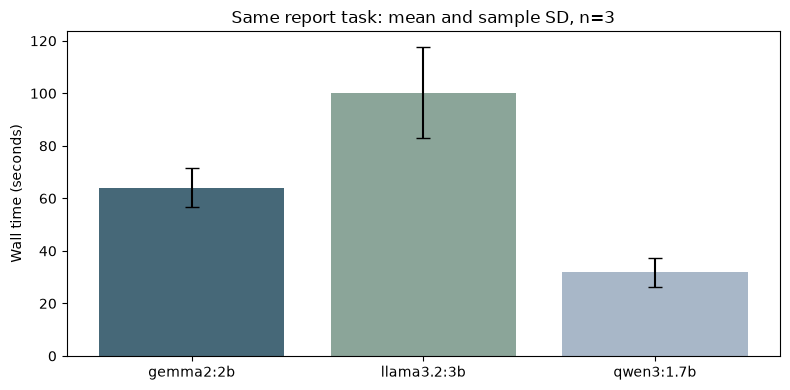

In [3]:
summary = df.groupby('model').agg(mean_seconds=('seconds','mean'), std_seconds=('seconds','std'), min_seconds=('seconds','min'), max_seconds=('seconds','max'), mean_load_seconds=('load_seconds','mean'))
display(summary.round(2))
plt.figure(figsize=(8,4))
plt.bar(summary.index, summary['mean_seconds'], yerr=summary['std_seconds'], capsize=5, color=['#466878','#8ba599','#a8b7c8'])
plt.ylabel('Wall time (seconds)')
plt.title('Same report task: mean and sample SD, n=3')
plt.tight_layout()
plt.show()

## 4. 원본 대조 평가

Codex가 모든 실제 답변을 원본 코드와 대조했습니다. 독립된 사람 평가가 아니며, 자동 키워드 점수도 아닙니다. 기준별 충족 여부와 인용·형식을 따로 기록합니다.

- 역할: 기획·검토=4B, 분석·작성=1.7B를 정확히 연결
- 주소: OLLAMA_BASE_URL 필수
- 인증: OLLAMA_API_KEY 선택 사항
- 경로: GET /api/tags
- 누락: 필요한 모델과 설치된 모델을 비교
- 한계: 코드만으로 배포 완료와 생성 품질 확인 불가

판정은 `충족 / 부분 / 누락 / 오류`입니다. 부분 설명을 완전한 정답으로 세지 않습니다. 종합 점수로 합산하지 않습니다.

In [4]:
display(pd.DataFrame(snapshot['evaluation']['calls']))

,검토메모,경로,누락검사,모델,문자수,문장인용,역할,인증,주소,한계,회차
0,"인증키 필수, 누락 검사 미구현이라고 잘못 설명. 역할별 모델명 없음.",누락,오류,qwen3:1.7b,219,누락,누락,오류,충족,충족,1
1,1회차와 답변 동일. 인증키와 모델 누락 검사 오류 반복.,누락,오류,qwen3:1.7b,219,누락,누락,오류,충족,충족,2
2,주소 필수는 맞지만 HTTP도 허용하는 코드에 HTTPS 필수 조건을 추가. 인증키...,누락,오류,qwen3:1.7b,253,누락,누락,오류,오류,충족,3
3,역할별 모델명 누락. 모델 사용 가능 여부만 설명. 성능 기준 배정이라는 근거 없는...,누락,부분,gemma2:2b,611,누락,누락,누락,누락,부분,1
4,두 모델명은 제시했으나 역할에 연결하지 않음. 주소 변수·모델 사용 가능 여부는 언...,누락,부분,gemma2:2b,530,누락,부분,누락,부분,부분,2
5,주소 설정 필요는 명확. 모델명만 나열하고 역할 배정·선택 인증·검사 경로를 빠뜨림...,누락,누락,gemma2:2b,457,누락,부분,누락,충족,부분,3
6,역할을 모델 연결 기능으로 혼동. check_connection 대신 ollama_...,오류,누락,llama3.2:3b,985,누락,오류,누락,부분,누락,1
7,모든 역할을 연결 API로 설명. 인증키를 필요 조건으로 추가. 서버 상태·연결·인...,누락,누락,llama3.2:3b,1170,누락,오류,오류,부분,충족,2
8,인용한 코드에 기획·분석 배정 일부만 있음. 문장 중 태국어 혼입. 코드가 있다는 ...,누락,누락,llama3.2:3b,1025,부분,부분,부분,부분,충족,3


## 5. 모델별 장점과 아쉬운 점

### 무엇과 비교했나
Qwen3 1.7B, Gemma 2 2B, Llama 3.2 3B에 같은 코드와 같은 한국어 작성 지시를 제공했다. 한 과제를 모델마다 3회 실행했다. 실제 양자화는 Qwen·Llama Q4_K_M, Gemma Q4_0이다. 다른 크기·양자화·템플릿이므로 동일 규모의 순수 모델 능력 비교가 아니라 이 PC에서 쓸 후보 구성의 비교다.

|모델|평균 요청 시간|상대적으로 나았던 점|아쉬운 점|
|---|---:|---|---|
|Qwen3 1.7B|31.86초|세 후보 중 요청 시간이 가장 짧았고 지정한 5개 제목 순서를 유지했다. 배포·품질 확인 불가도 3회 명시했다.|3회 모두 선택 인증키를 필수로, 구현된 누락 검사를 미구현으로 설명했다. 역할별 모델명과 근거 인용을 빠뜨렸다.|
|Gemma 2 2B|64.09초|문장 반복·다른 언어 혼입이 비교적 적었다. 2·3회에는 두 모델 이름, 3회에는 서버 주소 설정 필요를 설명했다.|역할과 모델을 정확히 연결하지 못했다. 선택 인증키, API 경로 등 핵심 조건을 자주 누락했다. 지정한 제목 형식과 문장별 인용도 지키지 못했다.|
|Llama 3.2 3B|100.31초|HTTP(S) 주소 조건을 설명했고 2·3회에는 배포·품질 확인 불가를 명시했다.|요청 시간이 가장 길었다. 반복 문장, 잘못된 역할 설명, 선택 인증키를 필수로 쓰는 오류가 있었다. 3회에는 태국어 혼입과 불필요한 코드 복사가 있었다.|

### 무엇이 더 좋았나
이 과제의 응답 시간과 제목 형식은 Qwen이 나았다. 읽기 쉬운 문장 초안 측면에서는 Gemma가 상대적으로 나았다는 관찰이다. 이는 독립된 사람의 블라인드 선호 평가가 아니다. Qwen은 답변 자체가 더 짧았으므로 시간 차이를 모델 고유의 추론 속도 차이로 단정하지 않는다.

내용 정확성에서는 세 후보 모두 핵심 누락 또는 오류가 있어 최종 보고서 자동 작성자로 바로 채택할 승자를 정할 수 없었다. 여섯 사실 기준을 모두 충족한 답변은 9개 중 0개였다. 따라서 이번 결과로 'Gemma 2가 가장 정확하다'거나 '큰 Llama가 더 좋다'고 결론 내리지 않는다. 초안 가독성을 개선할 추가 후보로 Gemma 2 2B를 남기되, 기존 앱의 역할 배정은 바꾸지 않았다.

### 원본과 대조한 오류 예
- Qwen: “OLLAMA_BASE_URL과 API 키 필수.” → E1은 주소만 필수이며 인증키는 존재할 때만 Bearer 헤더에 추가한다.
- Qwen: “모델 누락 검사 미구현.” → E1의 `required - available` 계산이 이미 누락 모델을 반환한다.
- Llama 2회: “모델 서버의 연결 상태를 확인하지 않습니다.” → E1의 `check_connection`이 서버에 요청하고 연결 실패를 처리한다.
- Gemma: 두 모델명을 쓴 경우에도 기획·검토=4B / 분석·작성=1.7B 연결이 빠졌다.

### 해석의 한계와 다음 실험
자료 1건뿐이고 회차별 seed만 달라 과제 다양성이 부족하다. Qwen 1·2회 답변은 동일했다. 오류가 반복되었다는 관찰이지 모든 보고서에서 같은 성능이라는 뜻은 아니다. 9회 모두 정상 종료(stop)였으며 출력 상한 도달로 잘린 결과는 없었다. 정상 종료가 내용 완성도를 보장하지는 않는다. 근거 인용도 Llama 3회의 코드 앞 ID 나열을 제외하면 없었고, 문장별 인용 요구를 충분히 지킨 답변은 없었다.

평가는 Codex가 소스와 답변을 대조한 기록이며, 독립 사람 평가나 사용자 만족도 실험이 아니다. 다음에는 여러 프로젝트 자료, 더 단순한 사실 추출 단계, 독립 사람 검토를 추가할 수 있다. 이번 실험은 작업자 초안 작성만 비교했으며 슈퍼바이저·검토자 성능 또는 최종 팀 전체 성능은 검증하지 않았다.


## 6. 모델의 실제 답변 전체

In [5]:
for r in records:
    print('\n'+'='*65)
    print(r['model'], '회차:',r['repeat'], '종료:',r['raw'].get('done_reason'))
    print(r['raw'].get('response',''))


gemma2:2b 회차: 1 종료: stop
## 프로젝트 보고서 초안

**1. 프로젝트 개요**

본 보고서는 한국어 프로젝트의 개요를 제시합니다. 프로젝트의 목표, 주요 기능, 그리고 개발 과정을 간략하게 설명합니다.

**2. 모델 역할 배정**

본 프로젝트에서는 다양한 모델을 사용하여 한국어 작업을 수행합니다.  `templates/model_settings.json` 파일에서 모델의 이름과 사용 목적을 정의하고, 모델의 성능을 기준으로 배정합니다.

**3. 서버 연결 조건**

프로젝트는 Ollama API를 이용하여 모델을 연결합니다.  `cloud_config.py` 파일에서 OLLAMA API 주소와 인증키를 설정합니다.  

**4. 연결 검사**

`check_connection()` 함수를 통해 모델 서버 연결 여부를 검사합니다.  `check_connection()` 함수는  `Ollama API`를 이용하여 모델 서버에 연결하고, 모델의 availability를 확인합니다.  

**5. 확인되지 않은 내용과 한계**

본 보고서는 배포 완료 여부와 생성 품질을 이 자료만으로 확인할 수 있는지 명시하지 않습니다.  배포 완료 여부와 생성 품질은 추가적인 정보를 통해 확인할 수 있습니다. 




llama3.2:3b 회차: 1 종료: stop
## 프로젝트 개요

이 프로젝트는 Streamlit Secrets를 사용하여 모델 연결과 세션별 작업 공간을 관리하는 모델 연결 프로젝트입니다. 프로젝트는 모델 서버와 클라우드에서 접속 가능한 주소를 확인하여 연결을 시도합니다.

## 모델 역할 배정

모델은 planner, analyst, organizer, writer, reviewer, slides로 나누어져 있으며 각 모델은 다른 모델과 연결되어 있습니다. 모델 연결은 Streamlit Secrets의 ollama_connection() 함수를 통해 모델 서버와 클라우드에서 접속 가능한 주소를 확인하여 연결을 시도합니다.

## 서

## 7. 다시 실험하는 방법

아래 셀은 기본으로 비활성화돼 있습니다. 실행 결과가 이미 존재하면 중복 호출하지 않습니다. 새 조건 실험은 별도 저장 폴더를 지정한 뒤 실행해야 합니다.

In [6]:
RUN_MODELS = False
if RUN_MODELS:
    import subprocess, sys
    project = notebook_path.resolve().parent.parent
    subprocess.run([sys.executable, str(project/'experiments/model_family_benchmark.py')], check=True)
else:
    print('저장된 결과만 확인했습니다. 새 모델 호출 없음.')

저장된 결과만 확인했습니다. 새 모델 호출 없음.
